In [1]:
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import pysdds
from opal import get_screen_from_h5, get_phasespace_from_h5

In [2]:
#sim_dir = "../data/opal/saved_runs/1nc_yag4"
sim_dir = "opal_sim/tmp_run/"
sdds = pysdds.read(os.path.join(sim_dir, 'input.sdds'))
print(sdds.describe())

SDDSFile: 1 pages, 3 parameters, 0 arrays, 46 columns, mode ascii, endianness little
 Page sizes: [735]
 Column mem usage: 0.2551 MB


/Users/jp/Repositories/pysdds/pysdds/readers/readers.py:2623: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_table(buf, encoding="ascii", **opts)


In [3]:
sdds.column_names

['t',
 's',
 'numParticles',
 'charge',
 'energy',
 'rms_x',
 'rms_y',
 'rms_s',
 'rms_px',
 'rms_py',
 'rms_ps',
 'emit_x',
 'emit_y',
 'emit_s',
 'mean_x',
 'mean_y',
 'mean_s',
 'ref_x',
 'ref_y',
 'ref_z',
 'ref_px',
 'ref_py',
 'ref_pz',
 'max_x',
 'max_y',
 'max_s',
 'xpx',
 'ypy',
 'zpz',
 'Dx',
 'DDx',
 'Dy',
 'DDy',
 'Bx_ref',
 'By_ref',
 'Bz_ref',
 'Ex_ref',
 'Ey_ref',
 'Ez_ref',
 'dE',
 'dt',
 'partsOutside',
 'DebyeLength',
 'plasmaParameter',
 'temperature',
 'rmsDensity']

In [4]:
df = sdds.columns_to_df()
df

,t,s,numParticles,charge,energy,rms_x,rms_y,rms_s,rms_px,rms_py,...,Ex_ref,Ey_ref,Ez_ref,dE,dt,partsOutside,DebyeLength,plasmaParameter,temperature,rmsDensity
0,-0.004011,0.000000,11,-2.685547e-11,0.000003,0.002464,0.001998,5.731760e-08,0.001373,0.001497,...,0.0,0.0,-45.609745,0.000003,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
1,-0.003837,0.000000,85,-2.075195e-10,0.000006,0.002591,0.002464,1.086623e-07,0.001300,0.001325,...,0.0,0.0,-45.667962,0.000005,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
2,-0.003663,0.000000,196,-4.785156e-10,0.000012,0.002590,0.002489,2.321873e-07,0.001326,0.001318,...,0.0,0.0,-45.726086,0.000011,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
3,-0.003488,0.000000,277,-6.762695e-10,0.000023,0.002593,0.002513,4.207719e-07,0.001337,0.001308,...,0.0,0.0,-45.784118,0.000019,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
4,-0.003314,0.000000,372,-9.082031e-10,0.000037,0.002650,0.002464,6.891212e-07,0.001347,0.001328,...,0.0,0.0,-45.842056,0.000031,0.000017,0.0,0.000000,0.000000,0.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
730,37.996116,11.376224,4096,-1.000000e-08,41.942903,0.003018,0.003098,1.062743e-03,0.016157,0.015572,...,0.0,0.0,0.000000,0.202472,0.010000,0.0,0.000025,71.137072,144.864287,1.138421e+15
731,38.096116,11.406201,4096,-1.000000e-08,41.942867,0.003014,0.003094,1.062763e-03,0.016141,0.015554,...,0.0,0.0,0.000000,0.202778,0.010000,0.0,0.000025,70.809851,144.561354,1.141774e+15
732,38.196116,11.436178,4096,-1.000000e-08,41.942830,0.003009,0.003090,1.062783e-03,0.016124,0.015537,...,0.0,0.0,0.000000,0.203084,0.010000,0.0,0.000024,70.484260,144.258934,1.145130e+15
733,38.296116,11.466155,4096,-1.000000e-08,41.942794,0.003005,0.003085,1.062803e-03,0.016108,0.015520,...,0.0,0.0,0.000000,0.203390,0.010000,0.0,0.000024,70.160024,143.957028,1.148497e+15


In [5]:
col_names = ['s', 'z']
design_path = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_DesignPath.dat'), 
    sep='\s+',
    skiprows=1,
    usecols=[0,3],
    names=col_names
)

In [6]:
design_path

,s,z
0,0.000458,0.000458
1,0.001679,0.001679
2,0.003484,0.003484
3,0.005680,0.005680
4,0.008126,0.008126
...,...,...
3826,11.458476,11.458476
3827,11.461474,11.461474
3828,11.464471,11.464471
3829,11.467469,11.467469


In [7]:
def z_to_s(z_value):
    idx = np.abs(design_path['z'] - z_value).argmin(axis=-1)
    return design_path['s'][idx]
z_to_s = np.vectorize(z_to_s)

In [8]:
# load the element positions
col_names = ['label', 'z', 'x', 'y']
ele_pos = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_ElementPositions.txt'), 
    sep='\s+', 
    index_col=0, 
    names=col_names
)

In [9]:
ele_pos['s'] = z_to_s(ele_pos['z'])
ele_pos

,z,x,y,s
label,,,,
BEGIN: CATHODE,0.000000,0,0,0.000458
END: CATHODE,0.050000,0,0,0.051189
BEGIN: YAG4,11.372000,0,0,11.371543
END: YAG4,11.382000,0,0,11.380536
BEGIN: SCREEN_CATHODE,0.001000,0,0,0.000458
END: SCREEN_CATHODE,0.011000,0,0,0.010730
BEGIN: GUN,0.000000,0,0,0.000458
END: GUN,0.292707,0,0,0.292681
BEGIN: LINAC_1,0.577433,0,0,0.576708


In [10]:
elements = {
    'dipoles': ['ED1', 'ED2', 'ED3', 'ED4'],
    'dipole_begin': 'ENTRY EDGE: ',
    'dipole_end': 'EXIT EDGE: ',
    'quads':  ['DQ4', 'DQ5', 'DQ6', 'DQ7'],
    'quad_begin':  'BEGIN: ',
    'quad_end': 'END: ',
    'rquads':  ['RQ1', 'RQ2'],
    'rquad_begin':  'BEGIN: ',
    'rquad_end': 'END: ',
    'linacs': ['GUN', 'LINAC_1', 'LINAC_2', 'LINAC_3', 'LINAC_5'],
    'linac_begin': 'BEGIN: ',
    'linac_end': 'END: ',
    'solenoids': [],
    'solenoid_begin': 'BEGIN: ',
    'solenoid_end': 'END: ',
}

In [11]:
def z_to_s(s_array, z_array, z_value):
    idx = (np.abs(z_array - z_value)).argmin()
    return s_array[idx]

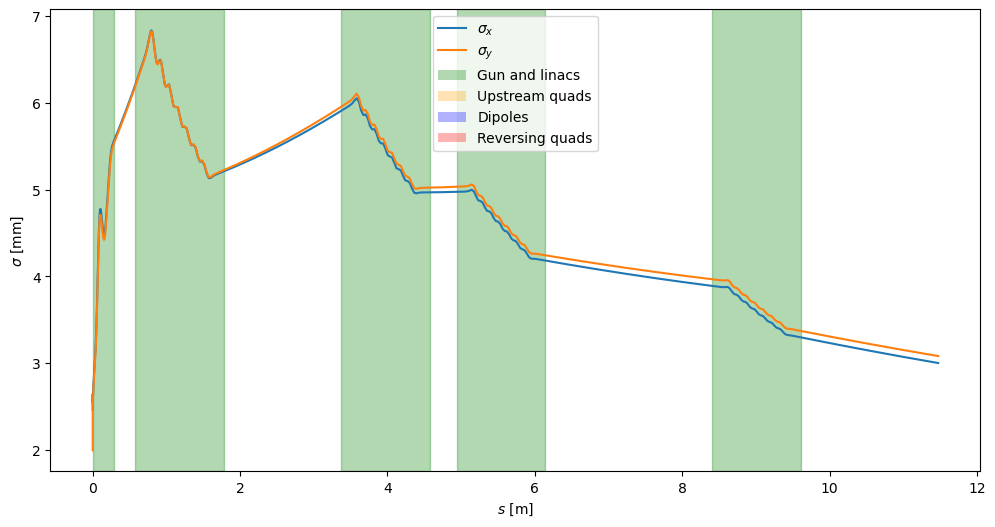

In [12]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(df['s'], df['rms_x']*1e3, label='$\sigma _x$')
ax.plot(df['s'], df['rms_y']*1e3, label='$\sigma _y$')
plt.legend()
old_handles, old_labels = ax.get_legend_handles_labels()
for linac in elements['linacs']:
    begin = ele_pos.at[elements['linac_begin'] + linac, 's']
    end = ele_pos.at[elements['linac_end'] + linac, 's']
    ax.axvspan(begin, end, alpha=0.3 , color='green')
# for quad in elements['quads']:
#    begin = ele_pos.at[elements['quad_begin'] + quad, 's']
#    end = ele_pos.at[elements['quad_end'] + quad, 's']
#    ax.axvspan(begin, end, alpha=0.3 , color='orange')
# for quad in elements['rquads']:
#    begin = ele_pos.at[elements['rquad_begin'] + quad, 's']
#    end = ele_pos.at[elements['rquad_end'] + quad, 's']
#    ax.axvspan(begin, end, alpha=0.3 , color='red')
# for dipole in elements['dipoles']:
#     begin = ele_pos.at[elements['dipole_begin'] + dipole, 's']
#     end = ele_pos.at[elements['dipole_end'] + dipole, 's']
#     ax.axvspan(begin, end, alpha=0.3, color='blue')

# ax.set_ylim(0, 1)
#ax.set_xlim(0, 1)
ax.set_xlabel('$s$ [m]')
ax.set_ylabel('$\sigma$ [mm]')

#legend
legend_elements = [
    Patch(facecolor='green', alpha=0.3, label='Gun and linacs'),
    Patch(facecolor='orange', alpha=0.3, label='Upstream quads'),
    Patch(facecolor='blue', alpha=0.3, label='Dipoles'),
    Patch(facecolor='red', alpha=0.3, label='Reversing quads'),
]

plt.legend(handles=old_handles+legend_elements, loc='upper center')
plt.show()

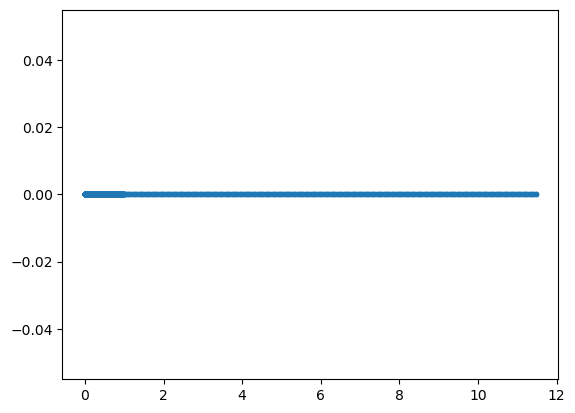

In [13]:
plt.plot(df['ref_z'], df['ref_x'], '.')
#plt.xlim(15, 22)

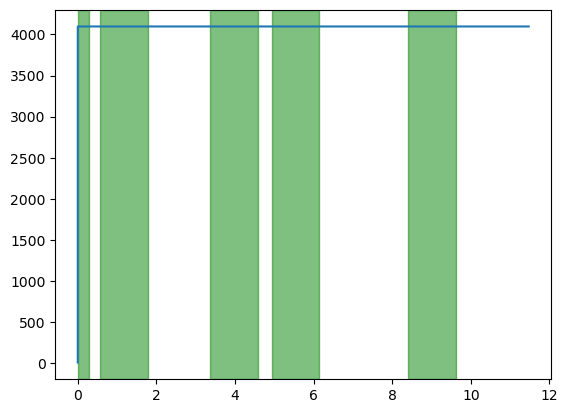

In [14]:
plt.plot(df['ref_z'], df['numParticles'])
for linac in elements['linacs']:
    begin = ele_pos.at[elements['linac_begin'] + linac, 's']
    end = ele_pos.at[elements['linac_end'] + linac, 's']
    plt.axvspan(begin, end, alpha=0.5 , color='green')
# for dipole in elements['dipoles']:
#    begin = ele_pos.at[elements['dipole_begin'] + dipole, 's']
#    end = ele_pos.at[elements['dipole_end'] + dipole, 's']
#    plt.axvspan(begin, end, alpha=0.5 )
# for quad in elements['quads']:
#     begin = ele_pos.at[elements['quad_begin'] + quad, 's']
#     end = ele_pos.at[elements['quad_end'] + quad, 's']
#     plt.axvspan(begin, end, alpha=0.5 , color='orange')

In [15]:
df['energy'].to_numpy()

array([3.44259503e-06, 5.98356457e-06, 1.15832788e-05, 2.30418953e-05,
       3.73137516e-05, 5.71926046e-05, 8.22852406e-05, 1.08183228e-04,
       1.38269026e-04, 1.69593204e-04, 2.03536451e-04, 2.43569071e-04,
       2.89424481e-04, 3.35445140e-04, 3.82199100e-04, 4.33592237e-04,
       4.89296384e-04, 5.52690937e-04, 6.14269735e-04, 6.81861017e-04,
       7.48780781e-04, 8.28678511e-04, 9.13945804e-04, 9.94060003e-04,
       1.08289953e-03, 1.16239343e-03, 1.25267455e-03, 1.34452256e-03,
       1.43331269e-03, 1.54183158e-03, 1.64815049e-03, 1.75850781e-03,
       1.88468898e-03, 1.99542812e-03, 2.12436059e-03, 2.23204235e-03,
       2.34959680e-03, 2.47523169e-03, 2.61236781e-03, 2.74989149e-03,
       2.88749005e-03, 3.03315344e-03, 3.19153007e-03, 3.33539941e-03,
       3.48479932e-03, 3.65169646e-03, 3.81466139e-03, 1.06697985e-02,
       5.98812523e-02, 1.46357825e-01, 2.61641870e-01, 3.97439938e-01,
       5.47301565e-01, 7.06467778e-01, 8.71330367e-01, 1.03899450e+00,
      

In [16]:
yag4 = get_screen_from_h5(os.path.join(sim_dir, 'YAG4.h5'))

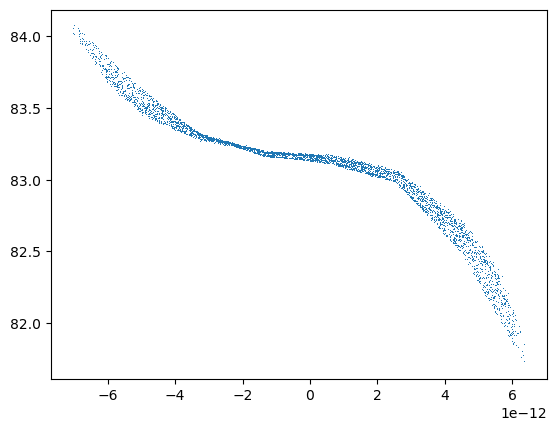

In [17]:
plt.plot(yag4['t'] - yag4['t'].mean(), yag4['pz'], ',')

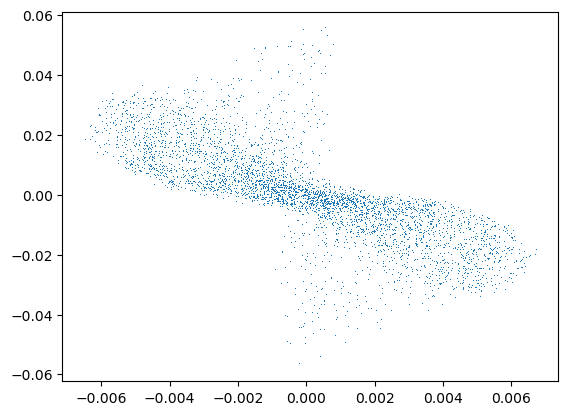

In [18]:
plt.plot(yag4['x'], yag4['px'], ',')

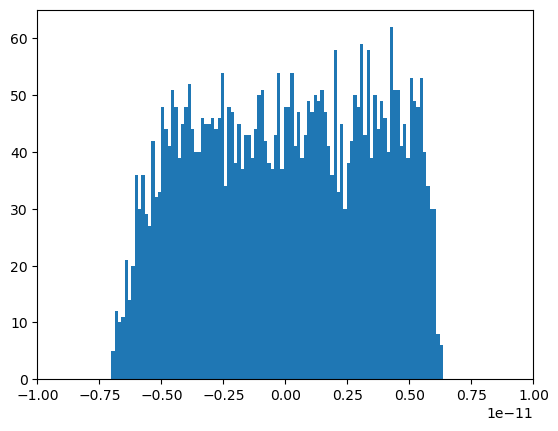

In [19]:
plt.hist(yag4['t']-yag4['t'].mean(), bins=100)
plt.xlim(-1e-11, 1e-11)
plt.show()

In [20]:
test = get_phasespace_from_h5(os.path.join(sim_dir, 'CATHODE_SCREEN.h5'))

In [21]:
test['z'].mean()

np.float64(-4.0943201240057055e-24)

In [22]:
test['x'].std()


np.float64(0.0025395944652050998)

In [23]:
test['y'].std()

np.float64(0.0025343865073797957)

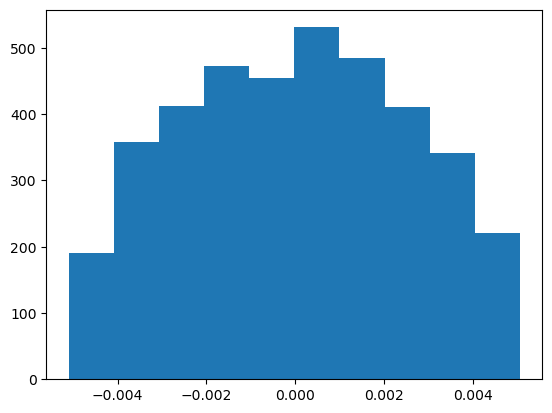

In [24]:
plt.hist(test['y'], bins=10)
plt.show()

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-5.06591532e-03, -4.86303743e-03, -4.66015954e-03, -4.45728165e-03,
        -4.25440376e-03, -4.05152587e-03, -3.84864798e-03, -3.64577009e-03,
        -3.44289220e-03, -3.24001431e-03, -3.03713642e-03, -2.83425853e-03,
        -2.63138064e-03, -2.42850276e-03, -2.22562487e-03, -2.02274698e-03,
        -1.81986909e-03, -1.61699120e-03, -1.41411331e-03, -1.21123542e-03,
        -1.00835753e-03, -8.05479641e-04, -6.02601751e-04, -3.99723862e-04,
        -1.96845973e-04,  6.03191635e-06,  2.08909806e-04,  4.11787695e-04,
         6.14665584e-04,  8.17543473e-04,  1.02042136e-03,  1.22329925e-03,
         1.42617714e-03,  1.62905503e-03,  1.83193292e-03,  2.03481081e-03,
         2.23768870e-03,  2.44056659e-03,  2.64344448e-03,  2.84632

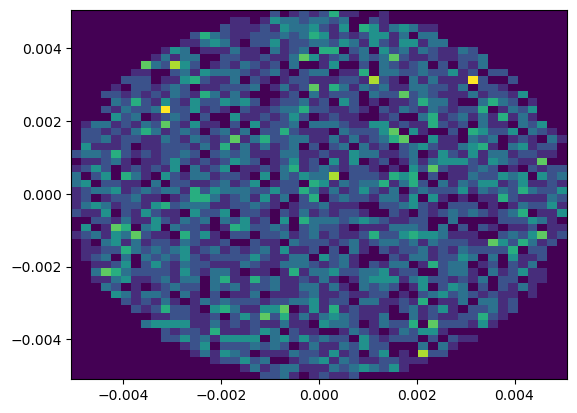

In [25]:
plt.hist2d(test['x'], test['y'], bins=50)

In [26]:
initial_dist = pd.read_csv(
    os.path.join(sim_dir, 'data', 'input_DIST_1.dat'),
    sep='\s+',
    skiprows=1,
    names=['x', 'px', 'y', 'py', 't', 'pz', 'bin']
)

In [27]:
initial_dist

,x,px,y,py,t,pz,bin
0,-0.001861,0.002330,-0.001432,0.000166,-1.514583e-13,0.000151,1
1,0.002300,-0.001525,0.003414,-0.001757,-2.158638e-13,0.000260,1
2,-0.001696,0.001090,0.001512,-0.000837,-2.167986e-13,0.001895,1
3,-0.001177,0.000178,0.003559,0.001918,-2.719160e-13,0.001331,1
4,0.002475,-0.001806,0.000860,-0.001488,-2.879473e-13,0.000043,1
...,...,...,...,...,...,...,...
4091,-0.000933,0.000665,0.000760,-0.001859,-8.393516e-12,0.001258,5
4092,0.004803,-0.002089,0.001381,0.001042,-8.400541e-12,0.000175,5
4093,0.004200,0.001382,-0.002338,0.001673,-8.410067e-12,0.000877,5
4094,-0.002669,-0.002183,0.002354,-0.000179,-8.435697e-12,0.000827,5


(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([-4.98831881e-03, -4.78896182e-03, -4.58960482e-03, -4.39024783e-03,
        -4.19089083e-03, -3.99153384e-03, -3.79217684e-03, -3.59281985e-03,
        -3.39346285e-03, -3.19410586e-03, -2.99474886e-03, -2.79539186e-03,
        -2.59603487e-03, -2.39667787e-03, -2.19732088e-03, -1.99796388e-03,
        -1.79860689e-03, -1.59924989e-03, -1.39989290e-03, -1.20053590e-03,
        -1.00117891e-03, -8.01821910e-04, -6.02464915e-04, -4.03107919e-04,
        -2.03750924e-04, -4.39392850e-06,  1.94963067e-04,  3.94320062e-04,
         5.93677058e-04,  7.93034053e-04,  9.92391049e-04,  1.19174804e-03,
         1.39110504e-03,  1.59046203e-03,  1.78981903e-03,  1.98917603e-03,
         2.18853302e-03,  2.38789002e-03,  2.58724701e-03,  2.78660

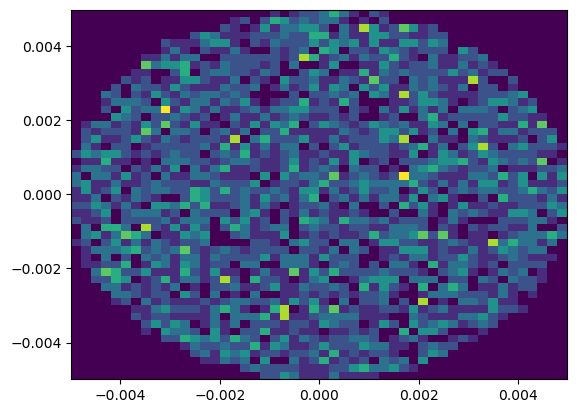

In [28]:
plt.hist2d(initial_dist['x'], initial_dist['y'], bins=50)

(array([ 1.,  0.,  0.,  0.,  0.,  1.,  0.,  6.,  7., 10.,  6., 10.,  8.,
        15., 16., 15., 14., 21., 27., 28., 41., 36., 50., 41., 58., 49.,
        49., 57., 46., 47., 59., 61., 62., 62., 67., 81., 67., 64., 68.,
        71., 73., 62., 63., 66., 76., 88., 66., 99., 79., 67., 76., 88.,
        68., 69., 62., 84., 72., 71., 70., 73., 77., 67., 65., 68., 64.,
        64., 69., 63., 42., 75., 63., 51., 58., 45., 47., 44., 46., 48.,
        44., 43., 40., 26., 25., 14., 16.,  5.,  9.,  7.,  3.,  2.,  3.,
         1.,  3.,  2.,  1.,  1.,  0.,  0.,  0.,  2.]),
 array([5.47947082e-06, 5.47947082e-06, 5.47947082e-06, 5.47947082e-06,
        5.47947082e-06, 5.47947082e-06, 5.47947082e-06, 5.47947082e-06,
        5.47947082e-06, 5.47947082e-06, 5.47947082e-06, 5.47947082e-06,
        5.47947082e-06, 5.47947082e-06, 5.47947082e-06, 5.47947082e-06,
        5.47947082e-06, 5.47947082e-06, 5.47947082e-06, 5.47947082e-06,
        5.47947082e-06, 5.47947082e-06, 5.47947082e-06, 5.47947082e-06,
  

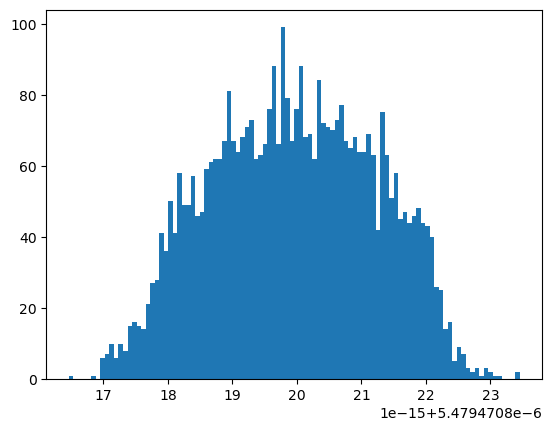

In [29]:
plt.hist(initial_dist['px']**2+initial_dist['py']**2+initial_dist['pz']**2, bins=100)

In [30]:
initial_dist['pz'].min()

np.float64(2.033074102e-07)

In [31]:
mass = 0.510999e6
gamma_beta = (np.sqrt(initial_dist['px']**2+initial_dist['py']**2+initial_dist['pz']**2)).mean()
gamma_beta*mass

np.float64(1196.1602317255122)

In [32]:
energy_k = (np.sqrt(1+gamma_beta**2)-1)*mass
energy_k

np.float64(1.400000136931763)